# 14 – Phase 4: higher input resolution

**Question:** does feeding the network the images **upsampled** to 320 or 384 px help, compared with the native 256 px?

**Why it could help.** Upsampling adds no information: the new pixels are bilinear mixtures of the old ones. What changes is how much of that information the network can use. ConvNeXt's first layer cuts the image into 4×4 blocks and summarises each block into one vector; then it halves the resolution three more times:

| input | after the stem | stage 2 | stage 3 | stage 4 |
|---|---|---|---|---|
| 256 px | 64×64 | 32×32 | 16×16 | 8×8 |
| 320 px | 80×80 | 40×40 | 20×20 | 10×10 |
| 384 px | 96×96 | 48×48 | 24×24 | 12×12 |

- A spiral arm 2–3 px wide falls inside a single 4×4 block at 256 px, mixed with the surrounding sky. At 384 px the same arm spans 3–4.5 px and is split across more blocks, so the early layers can resolve it before the resolution is reduced.
- Our main errors are exactly about fine structure: tight ↔ loose spiral, and disturbed → loose spiral.
- The ImageNet-pretrained filters are also used to objects that fill much of the frame. Our galaxies are often small, so enlarging them brings them closer to that scale.

**Runs** (everything else identical: the reference configuration of notebook 13 = V4 without class weights and without lines/rectangles, 25 epochs, batch 32):

| run | input size | relative cost |
|---|---|---|
| `ref_256` | 256 (native) | 1× (≈ 16 min) |
| `ref_320` | 320 | ≈ 1.6× (≈ 25 min) |
| `ref_384` | 384 | ≈ 2.25× (≈ 35 min) |

`ref_256` is needed because the reference configuration has never been trained as such: notebook 13 trained V4 *with* class weights and lines (R0) and each of them removed *separately*.

**Same pre-processing everywhere.** Every image the network sees is upsampled in the same way:
- training images;
- both validations;
- the test.

The network learns its filters at one scale, so it must be evaluated at that same scale. In training, the random augmentations are applied **at the native 256 px, before** the upsampling. This way:
- a blur of σ = 1 px, the noise grain and the image framing mean the same thing at every input size;
- training images are altered the way the test images are (altered at 256 px, then upsampled by us).

**Decision rule.** Run-to-run noise is ≈ 0.005–0.01 (notebook 13), so a resolution is adopted only if it beats `ref_256` by **≳ 0.01 on both validations**, on most folds. A smaller gain does not justify 1.6–2.25× the training time.

**Time:** ≈ 1 h 20 min in total. Run it in `tmux`, from the **VS Code terminal** (which is inside Ubuntu):
```
tmux new -s phase4
cd ~/ANN-DL-Challenge/families/elia && source ../../.venv/bin/activate
jupyter nbconvert --to notebook --execute --inplace --ExecutePreprocessor.timeout=-1 14_phase4_resolution.ipynb
```
Detach with `Ctrl+B`, release, then `D`; reattach with `tmux attach -t phase4`. Completed runs are skipped if the notebook is restarted.

## 0. Setup

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
from sklearn.metrics import f1_score

import train_lib as T
import common as C

plt.rcParams["figure.dpi"] = 80
SMOKE_TEST = False          # True = tiny run (few images, 1 epoch, fold 0) only to check that the code works
data = T.load_data(smoke_test=SMOKE_TEST)
print("device:", T.DEVICE, "| outputs:", T.OUT_DIR)

loaded 2995 training images (+ shifted versions) in 6s
device: cuda | outputs: /home/elia/ANN-DL-Challenge/families/elia/outputs


## 1. What upsampling does to an image

The same galaxy at 256, 320 and 384 px, with a zoom on its centre: the 64×64 central pixels of the original, i.e. the same region of the sky in all three.

**Check:**
- no new detail appears;
- the edges become smoother, because every new pixel is a mix of its neighbours;
- the structure now spans more pixels.

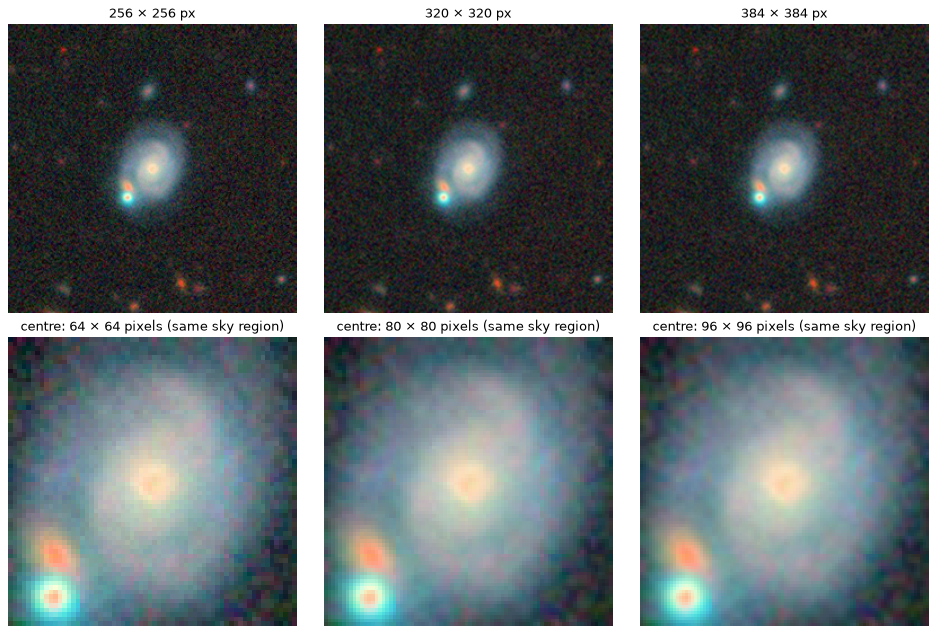

In [2]:
idx = int(np.where(data["y"] == 6)[0][0])           # a tight spiral
fig, axes = plt.subplots(2, 3, figsize=(12, 8))
for j, s in enumerate([256, 320, 384]):
    x = T.to_float(data["X_clean"][idx:idx + 1], s)[0].permute(1, 2, 0).cpu().numpy()
    c, h = s // 2, int(32 * s / 256)
    axes[0, j].imshow(x); axes[0, j].set_title(f"{s} × {s} px")
    axes[1, j].imshow(x[c - h:c + h, c - h:c + h], interpolation="nearest")
    axes[1, j].set_title(f"centre: {2 * h} × {2 * h} pixels (same sky region)")
for ax in axes.ravel():
    ax.axis("off")
plt.tight_layout(); plt.show()

> **Comment: upsampling, checked.** The bottom row shows the same 64×64 sky region of the original.
> - At 256 px it is 64×64 pixels, at 320 px 80×80, at 384 px 96×96.
> - No new detail appears: the spiral arms and the two stars are exactly as visible as before.
> - The image is only smoother: the "blocks" of the original pixels disappear, because every new pixel is a mix of its neighbours.
>
> This is exactly what we expected: the information is the same, only spread over more pixels.

## 2. The experiments

In [3]:
EXPERIMENTS = [
    T.reference_config(),
    T.reference_config(run_name="ref_320", note="reference at 320 px", img_size=320),
    T.reference_config(run_name="ref_384", note="reference at 384 px", img_size=384),
]
if SMOKE_TEST:
    for cfg in EXPERIMENTS:
        cfg.update(run_name=cfg["run_name"] + "_SMOKE", epochs=1, folds=[0], batch_size=16)

KEYS = ["run_name", "img_size", "epochs", "batch_size", "geo_p", "hue_p", "sat_p", "blur_p", "blur_sigma",
        "noise_p", "lines_p", "patch_p", "class_weight_power"]
pd.DataFrame(EXPERIMENTS)[KEYS]

,run_name,img_size,epochs,batch_size,geo_p,hue_p,sat_p,blur_p,blur_sigma,noise_p,lines_p,patch_p,class_weight_power
0,ref_256,256,25,32,1.0,0.5,1.0,0.5,"(0.3, 2.0)",0.25,0.0,0.0,0.0
1,ref_320,320,25,32,1.0,0.5,1.0,0.5,"(0.3, 2.0)",0.25,0.0,0.0,0.0
2,ref_384,384,25,32,1.0,0.5,1.0,0.5,"(0.3, 2.0)",0.25,0.0,0.0,0.0


In [4]:
results = {}
for cfg in EXPERIMENTS:
    results[cfg["run_name"]] = T.run_experiment(cfg, data)

loaded 14736 test images in 18s


ref_256 | fold 0 | epoch  1 | train loss 2.019 | F1 clean 0.450 | F1 shifted 0.454 | 31s


ref_256 | fold 0 | epoch  2 | train loss 1.514 | F1 clean 0.694 | F1 shifted 0.675 | 5s


ref_256 | fold 0 | epoch  3 | train loss 1.257 | F1 clean 0.776 | F1 shifted 0.762 | 5s


ref_256 | fold 0 | epoch  4 | train loss 1.195 | F1 clean 0.770 | F1 shifted 0.773 | 5s


ref_256 | fold 0 | epoch  5 | train loss 1.134 | F1 clean 0.775 | F1 shifted 0.786 | 5s


... (382 outputs left out)

ref_384 | fold 4 | epoch 23 | train loss 0.778 | F1 clean 0.841 | F1 shifted 0.837 | 10s


ref_384 | fold 4 | epoch 24 | train loss 0.776 | F1 clean 0.844 | F1 shifted 0.837 | 10s


ref_384 | fold 4 | epoch 25 | train loss 0.777 | F1 clean 0.844 | F1 shifted 0.837 | 10s



ref_384 | fold 4 with TTA: F1 clean 0.8581 | F1 shifted 0.8566 | 6.4 min

ref_384 done in 32.2 min: OOF F1 clean 0.8537 | shifted 0.8534


> **Comment: the runs.**
>
> | run | time |
> |---|---|
> | `ref_256` | 15.9 min |
> | `ref_320` | 23.2 min (×1.46) |
> | `ref_384` | 32.2 min (×2.0) |
>
> The cost grows a bit less than the number of pixels (×1.56 and ×2.25), because part of the time does not depend on the input size: loading, evaluation, Python overhead. At 384 px, batch 32 used about 8 GB of the 16 GB of the GPU, so it fits comfortably.

## 3. Comparison

Out-of-fold weighted F1 against `ref_256`. For context, the table also shows:
- `v4_repro` (R0 of notebook 13), i.e. the same recipe with class weights and lines/rectangles;
- `v4_fatemeh`;
- `e3_hue_blur`.

In [5]:
RUNS = [cfg["run_name"] for cfg in EXPERIMENTS]
REF = RUNS[0]

table = T.compare(RUNS[1:] + ["v4_repro", "v4_fatemeh", "e3_hue_blur"], reference=REF)
table.style.format("{:.4f}").background_gradient(subset=["Δ clean", "Δ shifted"], cmap="RdYlGn", vmin=-0.02, vmax=0.02)

,F1 clean,F1 shifted,Δ clean,Δ shifted,gap (clean − shifted),cigar clean,cigar shifted
run,,,,,,,
ref_256,0.8510,0.8452,0.0000,0.0000,0.0057,0.8235,0.8333
ref_320,0.8539,0.8507,0.0029,0.0055,0.0031,0.8403,0.8475
ref_384,0.8537,0.8534,0.0027,0.0082,0.0003,0.8403,0.8403
v4_repro,0.8498,0.8455,-0.0011,0.0003,0.0043,0.8333,0.8403
v4_fatemeh,0.8587,0.8513,0.0077,0.0060,0.0074,0.8361,0.8197
e3_hue_blur,0.8467,0.8458,-0.0043,0.0005,0.0009,0.7863,0.7899


In [6]:
# fold by fold, paired with ref_256 (same validation images): Δ = run − ref_256
def fold_f1(run):
    oof = pd.read_csv(T.OUT_DIR / run / "oof.csv")
    out = {}
    for val in ["clean", "shifted"]:
        P = oof[[f"p{c}_{val}" for c in range(C.N_CLASSES)]].to_numpy()
        out[val] = [f1_score(oof.label[oof.fold == k], P[oof.fold == k].argmax(1), average="weighted") for k in range(5)]
    return out

ref = fold_f1(REF)
rows = []
for run in RUNS[1:]:
    if not (T.OUT_DIR / run / "oof.csv").exists():
        continue
    f = fold_f1(run)
    for val in ["clean", "shifted"]:
        d = np.array(f[val]) - np.array(ref[val])
        rows.append({"run": run, "validation": val, **{f"fold {k}": d[k] for k in range(5)},
                     "mean Δ": d.mean(), "folds better": int((d > 0).sum())})
paired = pd.DataFrame(rows).set_index(["run", "validation"])
paired.style.format({**{f"fold {k}": "{:+.4f}" for k in range(5)}, "mean Δ": "{:+.4f}"}) \
      .background_gradient(subset=["mean Δ"], cmap="RdYlGn", vmin=-0.02, vmax=0.02)

> **Comment: comparison, and why the gain is smaller than it looks.**
>
> | run | OOF clean (Δ) | OOF shifted (Δ) | folds better (clean / shifted) |
> |---|---|---|---|
> | ref_256 | 0.8510 | 0.8452 | – |
> | ref_320 | 0.8539 (+0.003) | 0.8507 (+0.0055) | 2/5, 3/5 |
> | ref_384 | 0.8537 (+0.003) | 0.8534 (+0.008) | 2/5, **4/5** |
>
> - **Clean validation:** essentially no gain (+0.003), and only on 2 folds out of 5.
> - **Shifted validation:** a small gain, larger at 384 px (+0.008, 4/5 folds).
>
> **Most of the gain comes from fold 1.** There, 320 and 384 px are +0.02 better than 256, while on the other folds the differences go both ways and stay within ±0.01. Fold 1 is also where `ref_256` was unusually weak:
> - `ref_256` fold 1: 0.832;
> - `v4_repro` fold 1: 0.852, with almost the same recipe.
>
> So part of the "gain" is `ref_256` having an unlucky run on that fold, not resolution.
>
> **A direct measurement of the run-to-run noise.** `ref_256` and `v4_repro` differ only by class weights and lines/rectangles, both neutral in notebook 13. Their fold-by-fold differences on the clean validation are:
>
> | fold 0 | fold 1 | fold 2 | fold 3 | fold 4 | OOF |
> |---|---|---|---|---|---|
> | +0.002 | −0.020 | +0.005 | +0.010 | +0.009 | +0.001 |
>
> In other words:
> - **at the level of a single fold**, two practically identical recipes can differ by up to **±0.02**;
> - **on the whole OOF**, by a few thousandths.
>
> Counts like "4/5 folds better" are therefore weak evidence. The OOF difference is the more reliable number, with a noise of about ±0.005.

## 4. Per class: do the fine-structure classes gain?

If resolution helps for the reason above, the gains should concentrate on:
- **tight spiral (6)**;
- **loose spiral (7)**;
- **disturbed (0)**;
- possibly **barred spiral (5)**.

They should not appear on the smooth classes.

In [7]:
pc_clean, pc_shift = T.per_class(RUNS, "clean"), T.per_class(RUNS, "shifted")
delta = lambda t: t.sub(t[REF], axis=0).drop(columns=REF)
for name, t in [("CLEAN", pc_clean), ("SHIFTED", pc_shift)]:
    print(f"{name} validation: per-class F1 of {REF}, then Δ of each resolution")
    display(pd.concat([t[[REF]], delta(t)], axis=1).style.format("{:+.3f}").format("{:.3f}", subset=[REF])
            .background_gradient(subset=list(delta(t).columns), cmap="RdYlGn", vmin=-0.05, vmax=0.05))

CLEAN validation: per-class F1 of ref_256, then Δ of each resolution


,ref_256,ref_320,ref_384
0 disturbed,0.513,-0.017,-0.013
1 merging,0.895,+0.007,+0.014
2 round smooth,0.933,-0.000,-0.003
3 in-between smooth,0.927,+0.004,+0.001
4 cigar,0.824,+0.017,+0.017
5 barred spiral,0.869,-0.005,+0.008
6 tight spiral,0.782,+0.008,-0.002
7 loose spiral,0.745,+0.009,+0.005
8 edge-on no bulge,0.925,+0.009,+0.007
9 edge-on bulge,0.948,+0.001,-0.000


SHIFTED validation: per-class F1 of ref_256, then Δ of each resolution


,ref_256,ref_320,ref_384
0 disturbed,0.482,-0.008,-0.003
1 merging,0.883,+0.015,+0.023
2 round smooth,0.934,-0.001,-0.006
3 in-between smooth,0.926,+0.003,-0.002
4 cigar,0.833,+0.014,+0.007
5 barred spiral,0.858,+0.013,+0.023
6 tight spiral,0.786,+0.001,+0.005
7 loose spiral,0.737,+0.007,+0.017
8 edge-on no bulge,0.924,+0.010,+0.010
9 edge-on bulge,0.943,+0.006,+0.005


> **Comment: per class, the hypothesis is not confirmed.** If resolution helped for the "fine structure" reason, the gains would concentrate on tight spiral, loose spiral and disturbed. They do not.
>
> **Tight spiral and disturbed** (clean / shifted, 320 and 384 px compared with 256):
> - tight spiral: −0.002 to +0.008, i.e. no change;
> - disturbed: −0.017 to −0.003, i.e. *slightly worse*.
>
> **Loose spiral and barred spiral** gain a little only on the shifted validation: at 384 px, +0.017 and +0.023.
>
> **The largest gains** are on merging (+0.014 / +0.023 at 384 px) and cigar (+0.017 / +0.007 to +0.014). These are not the classes whose errors are about fine detail: merging is two galaxies close together, cigar an elongated shape.
>
> Most of these per-class differences are 1–5 images, so they are within noise.

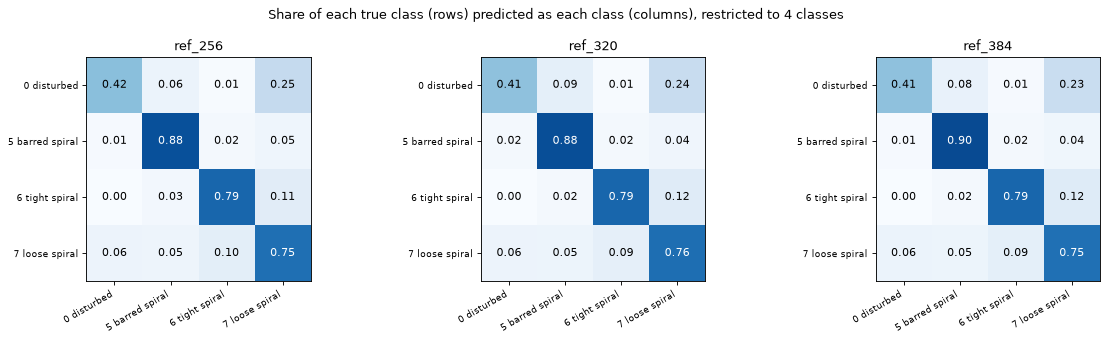

In [8]:
# confusion between the three spiral-like classes + disturbed (clean validation, OOF, rows = true class)
from sklearn.metrics import confusion_matrix
cls = [0, 5, 6, 7]
fig, axes = plt.subplots(1, len(RUNS), figsize=(5 * len(RUNS), 4.3))
for ax, run in zip(np.atleast_1d(axes), RUNS):
    oof = pd.read_csv(T.OUT_DIR / run / "oof.csv")
    pred = oof[[f"p{c}_clean" for c in range(C.N_CLASSES)]].to_numpy().argmax(1)
    cm = confusion_matrix(oof.label, pred, labels=list(range(C.N_CLASSES)))
    sub = cm[np.ix_(cls, cls)] / cm[cls].sum(1, keepdims=True).clip(min=1)
    ax.imshow(sub, cmap="Blues", vmin=0, vmax=1)
    for i in range(len(cls)):
        for j in range(len(cls)):
            ax.text(j, i, f"{sub[i, j]:.2f}", ha="center", va="center", color="white" if sub[i, j] > 0.5 else "black")
    names = [f"{c} {C.CLASSES[c]}" for c in cls]
    ax.set_xticks(range(len(cls)), names, rotation=30, ha="right", fontsize=8); ax.set_yticks(range(len(cls)), names, fontsize=8)
    ax.set_title(run)
plt.suptitle("Share of each true class (rows) predicted as each class (columns), restricted to 4 classes")
plt.tight_layout(); plt.show()

> **Comment: the spiral confusions do not change.** The three matrices are practically identical:
> - disturbed → loose spiral 0.23–0.25;
> - tight → loose 0.11–0.12;
> - loose → tight 0.09–0.10.
>
> Enlarging the image does not help the network separate these classes. The likely explanation is that the limit is in the **information** of the 256 px image and in the **labels**, not in the network's ability to read it.
>
> On the information: the arms of a tight spiral are often only 1–2 original pixels wide, and no interpolation recovers what the telescope did not resolve.
>
> On the labels: the boundary between tight and loose, and between loose and disturbed, is partly subjective. The `review` images, where the model and the label disagree, are concentrated exactly here.

## 5. Training curves and time

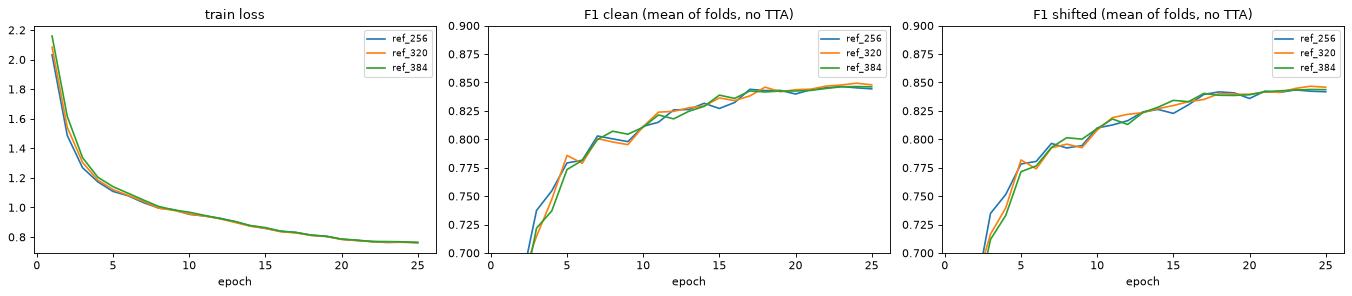

{'ref_256': '15.9 min', 'ref_320': '23.2 min', 'ref_384': '32.2 min'}


In [9]:
fig, axes = plt.subplots(1, 3, figsize=(17, 3.8))
for name in RUNS:
    f = T.OUT_DIR / name / "history.csv"
    if not f.exists():
        continue
    h = pd.read_csv(f).groupby("epoch").mean(numeric_only=True)
    axes[0].plot(h.index, h.train_loss, label=name)
    axes[1].plot(h.index, h.f1_clean, label=name)
    axes[2].plot(h.index, h.f1_shifted, label=name)
for ax, t in zip(axes, ["train loss", "F1 clean (mean of folds, no TTA)", "F1 shifted (mean of folds, no TTA)"]):
    ax.set_title(t); ax.set_xlabel("epoch"); ax.legend(fontsize=8)
axes[1].set_ylim(0.7, 0.9); axes[2].set_ylim(0.7, 0.9)
plt.tight_layout(); plt.show()
print({name: f"{r['minutes']:.1f} min" for name, r in results.items()})

> **Comment: curves.** The three runs follow the same curve, epoch by epoch, on all three panels:
> - same training loss;
> - same plateau at ≈ 0.845 (no TTA) from epoch ~20.
>
> Resolution changes neither the speed of learning nor the final level in a visible way.

## 6. Decision

| run | F1 clean (Δ) | F1 shifted (Δ) | folds better (clean / shifted) | minutes |
|---|---|---|---|---|
| ref_256 | 0.8510 | 0.8452 | – | 15.9 |
| ref_320 | 0.8539 (+0.003) | 0.8507 (+0.0055) | 2/5, 3/5 | 23.2 |
| ref_384 | 0.8537 (+0.003) | 0.8534 (+0.008) | 2/5, 4/5 | 32.2 |

- **Rule (≳ +0.01 on both validations): not passed.** The clean validation does not move (+0.003), and the shifted gain (+0.008 at 384 px) comes largely from fold 1, where `ref_256` had an unlucky run.
- **Do the gains concentrate on the spiral classes and disturbed?** No:
  - tight spiral does not change;
  - disturbed gets slightly worse;
  - the spiral confusions in the matrices are identical.
- **Chosen resolution: 256 px.** Higher resolution costs 1.5–2× the time for a gain within the noise. No Kaggle submission for this phase: among augmented models Kaggle has followed the clean validation, where nothing changed.

**What we learn.**
1. **ConvNeXt-Tiny is on a plateau** at OOF ≈ 0.85 (clean) whatever we change: augmentation (notebooks 11 and 13) or resolution (this notebook). All the remaining differences are of the order of the run-to-run noise.
2. **The run-to-run noise is now measured,** not just guessed (section 3): up to ±0.02 on a single fold, a few thousandths on the OOF. Future decisions should rely on the OOF difference (threshold ≈ 0.01) rather than on fold counts.
3. **The main errors are not a matter of how the network reads the image.** They are disturbed vs loose spiral and tight vs loose spiral. They are more likely a matter of **ambiguous or wrong labels** at the class boundaries.

**Next.** The largest effect seen so far is on the labels. On the 126 `review` images the models agree with the label only ~44% of the time, (Fatemeh's 0.859 → 0.879 only *excluded them from the evaluation*, so it is not a measured gain: the real effect of training without them is unknown and still to be measured). This must be done carefully: the validation has to stay the same for every model. Other options with a potentially larger effect than ±0.005:
- a larger backbone (ConvNeXt-Small);
- an ensemble with Davide's EfficientNetV2-S, which is genuinely different from ours.

A 384 px model can still be useful later as a *diverse* member of a final ensemble: it sees the galaxies at another scale, and its OOF on the shifted validation (0.853) is the best of our own runs.